# Poo : french cities

Origin data: [lien data.gouv.fr](https://www.data.gouv.fr/datasets/liste-des-communes-de-france-code-insee-codes-postaux-epci-population-superficie-62-indicateurs)

In [33]:
%reload_ext autoreload
%autoreload 2
from city import CityFr
import json
from operator import attrgetter
import pandas as pd

In [ ]:
# appel par positional argument
city = CityFr("Marseille", 886_040, "13000")
print(city)  # uses str() => city.__str__()
print("Name:", city.name)
print("Population:", city.population)
print("Zipcode:", city.zipcode)
print("Department:", city.department())
city  # uses repr() => city.__repr__()

Marseille (13000)
Name: Marseille
Population: 500000
Zipcode: 13000
Department: 


CityFr(name='Marseille', population=500000, zipcode='13000')

In [3]:
city.population += 200
print(city)

Marseille (13000)


In [4]:
# appel par keyword argument
city2 = CityFr(name="Nantes", population=300_000, zipcode="44000")
city2

CityFr(name='Nantes', population=300000, zipcode='44000')

In [14]:
# méthodes / attributs "cachées"
print(city.__class__)
print(type(city))

print(str(city))
print(repr(city))

print(str(city.zipcode))
print(repr(city.zipcode))

<class 'city.CityFr'>
<class 'city.CityFr'>
Marseille (13000)
CityFr(name='Marseille', population=500000, zipcode='13000')
13000
'13000'


In [16]:
city2 += 100
city2

CityFr(name='Nantes', population=300100, zipcode='44000')

In [20]:
# city2 += city # error linter + execution


## Atelier
- lire le fichier JSON des villes de plus de 100 000 habitants
- les charger dans une liste d'objets CityFr (list[CityFr])
- trier par population décroissante
- population totale
- filtrer les villes de plus de 500 000 habitants

In [23]:
with open('data/villes100k.json', encoding='UTF-8') as f:
    data = json.load(f)
data

[{'nom_standard': 'Nice',
  'nom_sans_pronom': 'Nice',
  'dep_code': '06',
  'dep_nom': 'Alpes-Maritimes',
  'code_postal': '06000',
  'population': 348085,
  'superficie_km2': 74},
 {'nom_standard': 'Aix-en-Provence',
  'nom_sans_pronom': 'Aix-en-Provence',
  'dep_code': '13',
  'dep_nom': 'Bouches-du-Rhône',
  'code_postal': '13100',
  'population': 147478,
  'superficie_km2': 188},
 {'nom_standard': 'Marseille',
  'nom_sans_pronom': 'Marseille',
  'dep_code': '13',
  'dep_nom': 'Bouches-du-Rhône',
  'code_postal': '13000',
  'population': 873076,
  'superficie_km2': 241},
 {'nom_standard': 'Caen',
  'nom_sans_pronom': 'Caen',
  'dep_code': '14',
  'dep_nom': 'Calvados',
  'code_postal': '14000',
  'population': 108200,
  'superficie_km2': 26},
 {'nom_standard': 'Dijon',
  'nom_sans_pronom': 'Dijon',
  'dep_code': '21',
  'dep_nom': "Côte-d'Or",
  'code_postal': '21000',
  'population': 159346,
  'superficie_km2': 42},
 {'nom_standard': 'Besançon',
  'nom_sans_pronom': 'Besançon',
  

In [25]:
cities: list[CityFr] = []
for city_dict in data:
    city_fr = CityFr(name=city_dict['nom_standard'], population=city_dict['population'], zipcode=city_dict['code_postal'])
    cities.append(city_fr)
cities[:5]

[CityFr(name='Nice', population=348085, zipcode='06000'),
 CityFr(name='Aix-en-Provence', population=147478, zipcode='13100'),
 CityFr(name='Marseille', population=873076, zipcode='13000'),
 CityFr(name='Caen', population=108200, zipcode='14000'),
 CityFr(name='Dijon', population=159346, zipcode='21000')]

In [28]:
cities.sort(key=lambda city: city.population, reverse=True)
cities[:5]

[CityFr(name='Paris', population=2133111, zipcode='75000'),
 CityFr(name='Marseille', population=873076, zipcode='13000'),
 CityFr(name='Lyon', population=522250, zipcode='69000'),
 CityFr(name='Toulouse', population=504078, zipcode='31100'),
 CityFr(name='Nice', population=348085, zipcode='06000')]

In [30]:
cities.sort(key=attrgetter('population'))
cities[:5]

[CityFr(name='Nancy', population=104260, zipcode='54100'),
 CityFr(name='Saint-Paul', population=105240, zipcode='97411'),
 CityFr(name='Mulhouse', population=106341, zipcode='68200'),
 CityFr(name='Argenteuil', population=107221, zipcode='95100'),
 CityFr(name='Caen', population=108200, zipcode='14000')]

In [31]:
total_population = sum(city.population for city in cities)
total_population

10232650

In [41]:
cities_500k = [ city for city in cities if city.population >= 500_000 ]
cities_500k

[CityFr(name='Toulouse', population=504078, zipcode='31100'),
 CityFr(name='Lyon', population=522250, zipcode='69000'),
 CityFr(name='Marseille', population=873076, zipcode='13000'),
 CityFr(name='Paris', population=2133111, zipcode='75000')]

In [43]:
cities_500k = list(filter(lambda city: city.population >= 500_000, cities))
cities_500k

[CityFr(name='Toulouse', population=504078, zipcode='31100'),
 CityFr(name='Lyon', population=522250, zipcode='69000'),
 CityFr(name='Marseille', population=873076, zipcode='13000'),
 CityFr(name='Paris', population=2133111, zipcode='75000')]

In [38]:
df_cities = pd.read_json(
    'data/villes100k.json', 
    orient='records',
    dtype={
        'dep_code': str,
        'code_postal': str,
    }
)
df_cities.head(6)

,nom_standard,nom_sans_pronom,dep_code,dep_nom,code_postal,population,superficie_km2
0,Nice,Nice,06,Alpes-Maritimes,06000,348085,74
1,Aix-en-Provence,Aix-en-Provence,13,Bouches-du-Rhône,13100,147478,188
2,Marseille,Marseille,13,Bouches-du-Rhône,13000,873076,241
3,Caen,Caen,14,Calvados,14000,108200,26
4,Dijon,Dijon,21,Côte-d'Or,21000,159346,42
5,Besançon,Besançon,25,Doubs,25000,119198,65


In [39]:
df_cities.info()

<class 'pandas.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   nom_standard     42 non-null     str  
 1   nom_sans_pronom  42 non-null     str  
 2   dep_code         42 non-null     str  
 3   dep_nom          42 non-null     str  
 4   code_postal      42 non-null     str  
 5   population       42 non-null     int64
 6   superficie_km2   42 non-null     int64
dtypes: int64(2), str(5)
memory usage: 2.4 KB


In [40]:
df_cities.describe()

,population,superficie_km2
count,4.200000e+01,42.000000
mean,2.436345e+05,63.190476
std,3.317333e+05,56.520766
min,1.042600e+05,6.000000
25%,1.196940e+05,26.500000
50%,1.477910e+05,48.500000
75%,2.139238e+05,72.500000
max,2.133111e+06,241.000000


In [44]:
total_population = df_cities.population.sum()
mean_population = df_cities.population.mean()
print("Total:", total_population)
print("Mean:", mean_population)

Total: 10232650
Mean: 243634.52380952382


In [50]:
df_cities = df_cities.sort_values('population', ascending=False)
df_cities

,nom_standard,nom_sans_pronom,dep_code,dep_nom,code_postal,population,superficie_km2
30,Paris,Paris,75,Paris,75000,2133111,105
2,Marseille,Marseille,13,Bouches-du-Rhône,13000,873076,241
26,Lyon,Lyon,69,Rhône,69000,522250,48
8,Toulouse,Toulouse,31,Haute-Garonne,31100,504078,118
0,Nice,Nice,06,Alpes-Maritimes,06000,348085,74
15,Nantes,Nantes,44,Loire-Atlantique,44200,323204,66
10,Montpellier,Montpellier,34,Hérault,34080,302454,57
24,Strasbourg,Strasbourg,67,Bas-Rhin,67000,291313,78
9,Bordeaux,Bordeaux,33,Gironde,33300,261804,50
21,Lille,Lille,59,Nord,59260,236710,35


In [51]:
df_cities = df_cities.sort_values(['dep_code', 'population'], ascending=[True, False])
df_cities

,nom_standard,nom_sans_pronom,dep_code,dep_nom,code_postal,population,superficie_km2
0,Nice,Nice,06,Alpes-Maritimes,06000,348085,74
2,Marseille,Marseille,13,Bouches-du-Rhône,13000,873076,241
1,Aix-en-Provence,Aix-en-Provence,13,Bouches-du-Rhône,13100,147478,188
3,Caen,Caen,14,Calvados,14000,108200,26
4,Dijon,Dijon,21,Côte-d'Or,21000,159346,42
5,Besançon,Besançon,25,Doubs,25000,119198,65
6,Brest,Brest,29,Finistère,29200,139619,49
7,Nîmes,Nîmes,30,Gard,30900,148104,161
8,Toulouse,Toulouse,31,Haute-Garonne,31100,504078,118
9,Bordeaux,Bordeaux,33,Gironde,33300,261804,50


In [47]:
df_cities_500k = df_cities.loc[df_cities.population >= 500_000]
df_cities_500k

,nom_standard,nom_sans_pronom,dep_code,dep_nom,code_postal,population,superficie_km2
2,Marseille,Marseille,13,Bouches-du-Rhône,13000,873076,241
8,Toulouse,Toulouse,31,Haute-Garonne,31100,504078,118
26,Lyon,Lyon,69,Rhône,69000,522250,48
30,Paris,Paris,75,Paris,75000,2133111,105


<Axes: xlabel='nom_standard'>

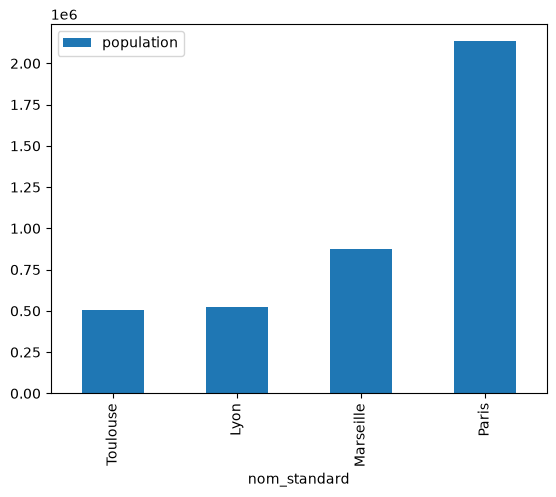

In [54]:
df_cities_500k[['nom_standard', 'population']] \
    .sort_values('population') \
    .set_index('nom_standard') \
    .plot(kind='bar')

## Classe vintage

In [57]:
class CityFr:
    """represents a french City with its name, population and zipcode
        
    Example:

        city = CityFr("Marseille", 886_040, "13000")
    """

    def __init__(self, name: str, population: int, zipcode: str):
        self.name = name
        self.population = population
        self.zipcode = zipcode

    # personnalisation de la builtin str
    # par défaut : __repr__ = __str__
    def __str__(self) -> str:
        return f"{self.name} ({self.zipcode})"

    def __repr__(self) -> str:
            return f"CityFr(name={self.name}, population={self.population}, zipcode={self.zipcode})"

    # surcharge d'opérateur +=, -=
    # def __iadd__(self, other: int) -> CityFr:   # python 3.14+
    def __iadd__(self, other: int) -> 'CityFr': # python <3.14
        self.population += other
        return self


    def department(self) -> str:
        match self.zipcode[:2]: 
            case "20" if int(self.zipcode) < 20200:
                # Corse du Sud
                return "2A"
            case "20":
                # Haute-Corse
                return "2B"
            case "97" | "98":
                # DOM/TOM : departement sur 3 chiffres
                return self.zipcode[:3]
            case _:
                return self.zipcode[:2]

In [58]:
city = CityFr("Marseille", 886_040, "13000")
print(city)  # uses str() => city.__str__()
print("Name:", city.name)
print("Population:", city.population)
print("Zipcode:", city.zipcode)
print("Department:", city.department())
city

Marseille (13000)
Name: Marseille
Population: 886040
Zipcode: 13000
Department: 13


CityFr(name=Marseille, population=886040, zipcode=13000)

In [ ]:
assert type(city) is CityFr
assert isinstance(city, CityFr)
assert isinstance(city, object) # car CityFr hérite de object